In [4]:
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Read the CSV file
weekend = pd.read_csv("data/Weekend2.csv")

# View the first 5 rows
weekend.head()

,Timestamp,How much do you enjoy hiking?,How much do you enjoy skiing or snowboarding?,"If you see a lake, river, or the sea, how likely are you to jump in?",How much do you enjoy watching sports events?,How much do you enjoy going to parties or clubs?,How much do you enjoy shopping?,How much do you enjoy deep conversations?,How much do you enjoy small talk and light social conversations?,How much do you like movies?,How much do you like exotic food?,Name/nickname if you would like to see with whom you get clustered
0,11/12/2026 8:50:53,9,10,9,6,7,2,9,4,4,9,Reto
1,11/12/2026 8:59:58,8,10,10,4,1,1,10,7,4,6,Zofia
2,11/12/2026 9:00:11,8,1,3,10,3,7,10,2,1,7,52!
3,11/12/2026 9:00:32,7,9,6,1,1,1,3,3,6,3,Alexandra
4,11/12/2026 9:00:48,4,1,1,5,3,9,9,8,9,7,Cat


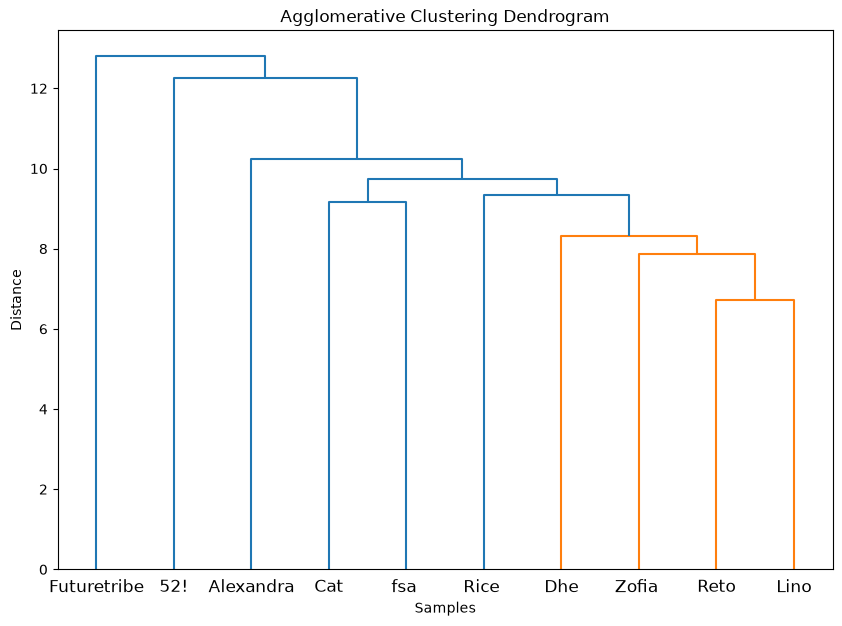

In [5]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

from scipy.cluster.hierarchy import linkage, dendrogram
#weekend = weekend.drop(weekend.index[0:6]) drop fake rows
X = weekend.select_dtypes(include=['int64', 'float64'])

HC = AgglomerativeClustering(n_clusters=3)
HC.fit(X)
dend = linkage(X, method='single')
plt.figure(figsize=(10, 7))
plt.title("Agglomerative Clustering Dendrogram")
plt.xlabel("Samples")
plt.ylabel("Distance")
dendrogram(dend, labels=weekend.loc[:, 'Name/nickname if you would like to see with whom you get clustered'].values)

plt.show()





Task: 
Check other linkage methods:
method='single'
method='complete'
method='ward'
And test different numbers of clusters.
Compare the results. Which clustering would you choose?

In [6]:
HC = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

labels = HC.fit_predict(X)
weekend['Cluster'] = labels

cluster_means = weekend.groupby('Cluster').mean(numeric_only=True)

display(cluster_means)
print(weekend['Cluster'].value_counts())

,How much do you enjoy hiking?,How much do you enjoy skiing or snowboarding?,"If you see a lake, river, or the sea, how likely are you to jump in?",How much do you enjoy watching sports events?,How much do you enjoy going to parties or clubs?,How much do you enjoy shopping?,How much do you enjoy deep conversations?,How much do you enjoy small talk and light social conversations?,How much do you like movies?,How much do you like exotic food?
Cluster,,,,,,,,,,
0,6.0,3.0,3.0,4.5,2.0,7.75,9.25,5.5,7.25,6.5
1,8.4,9.2,7.4,5.8,3.6,3.40,8.00,5.8,6.00,6.6
2,8.0,3.0,10.0,10.0,10.0,1.00,1.00,1.0,10.00,10.0


Cluster
1    5
0    4
2    1
Name: count, dtype: int64


PCA loadings (weights for each feature):


,PC1,PC2
How much do you enjoy hiking?,-0.195451,-0.002573
How much do you enjoy skiing or snowboarding?,-0.222436,-0.531531
"If you see a lake, river, or the sea, how likely are you to jump in?",-0.509497,-0.164472
How much do you enjoy watching sports events?,-0.220295,0.597430
How much do you enjoy going to parties or clubs?,-0.333730,0.388858
How much do you enjoy shopping?,0.548287,0.284897
How much do you enjoy deep conversations?,0.314187,-0.057445
How much do you enjoy small talk and light social conversations?,0.171870,-0.139731
How much do you like movies?,0.096976,0.077451
How much do you like exotic food?,-0.233566,0.268876


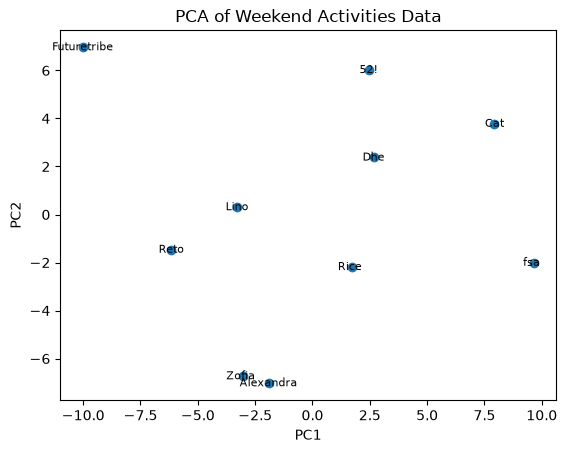

In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)


loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=X.columns
)
print("PCA loadings (weights for each feature):")
display(loadings)

fig, ax = plt.subplots()
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1])
for i in range(len(weekend)):
    plt.text(X_pca[i, 0], X_pca[i, 1], 
             weekend.loc[i, 'Name/nickname if you would like to see with whom you get clustered'],
             fontsize=8, ha="center", va="center")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA of Weekend Activities Data")
plt.show()


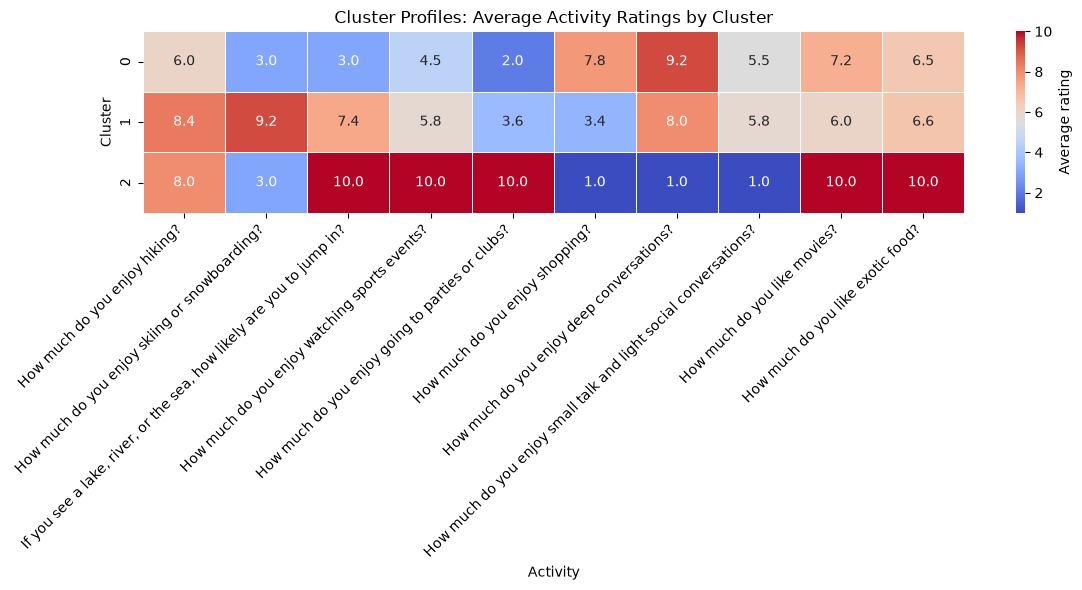

In [8]:
import seaborn as sns

import matplotlib.pyplot as plt

# Heatmap of cluster centroids to compare activity profiles by cluster
plt.figure(figsize=(12, 6))
sns.heatmap(
    cluster_means,
    annot=True,
    cmap="coolwarm",
    fmt=".1f",
    linewidths=0.5,
    cbar_kws={"label": "Average rating"}
)
plt.title("Cluster Profiles: Average Activity Ratings by Cluster")
plt.xlabel("Activity")
plt.ylabel("Cluster")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

  Name/nickname if you would like to see with whom you get clustered  \
0                                               Reto                   
1                                             Zofia                    
2                                                52!                   
3                                          Alexandra                   
4                                                Cat                   
5                                        Futuretribe                   
6                                                Dhe                   
7                                               Lino                   
8                                               fsa                    
9                                              Rice                    

   PCA_Cluster  
0            1  
1            1  
2            0  
3            1  
4            0  
5            2  
6            0  
7            1  
8            0  
9            1  

Cluster sizes:
PCA_

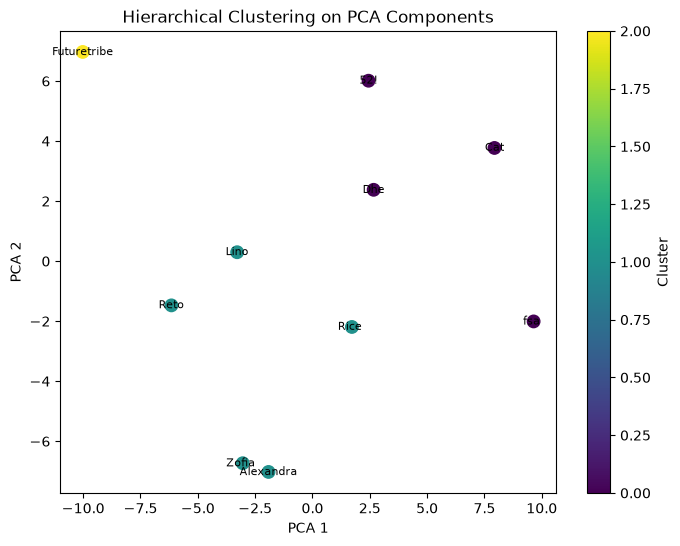

In [9]:
# Cluster on the 2D PCA space (PC1 and PC2)
pca_hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
pca_labels = pca_hc.fit_predict(X_pca)

weekend['PCA_Cluster'] = pca_labels

print(weekend[['Name/nickname if you would like to see with whom you get clustered', 'PCA_Cluster']])
print("\nCluster sizes:")
print(weekend['PCA_Cluster'].value_counts().sort_index())

# Plot clusters in PCA space
fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pca_labels,
    cmap='viridis',
    s=80
)

for i, name in enumerate(weekend['Name/nickname if you would like to see with whom you get clustered']):
    ax.text(X_pca[i, 0], X_pca[i, 1], name, fontsize=8, ha='center', va='center')

ax.set_xlabel('PCA 1')
ax.set_ylabel('PCA 2')
ax.set_title('Hierarchical Clustering on PCA Components')
plt.colorbar(scatter, ax=ax, label='Cluster')
plt.show()

k=2: silhouette score=0.178
k=3: silhouette score=0.169
k=4: silhouette score=0.155
k=5: silhouette score=0.112
k=6: silhouette score=0.095
k=7: silhouette score=0.094
k=8: silhouette score=0.064
k=9: silhouette score=0.034


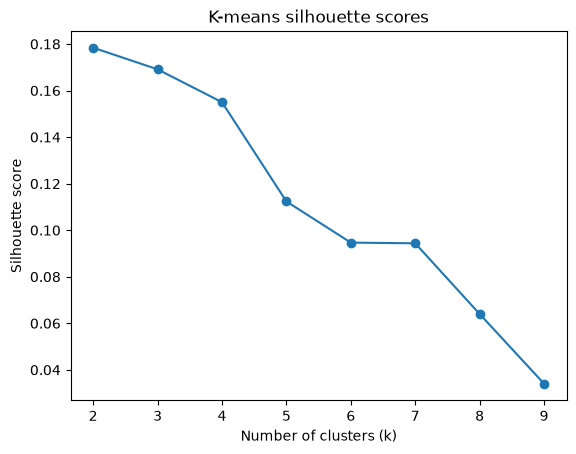

In [10]:
scores = {}
max_k = min(10, len(X) - 1)

for k in range(2, max_k + 1):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = kmeans.fit_predict(X)
    scores[k] = silhouette_score(X, labels_k)

for k, score in scores.items():
    print(f"k={k}: silhouette score={score:.3f}")

plt.plot(list(scores.keys()), list(scores.values()), marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("K-means silhouette scores")
plt.xticks(list(scores.keys()))
plt.show()

In [11]:
name_col = 'Name/nickname if you would like to see with whom you get clustered'
target_name = '52!'  # Change to '51!' if that is the intended name

matches = weekend[name_col].astype(str).str.strip() == target_name
if not matches.any():
    print(f"{target_name!r} was not found. Names in the data:")
    display(weekend[name_col])
else:
    row_index = weekend.index[matches][0]
    results = []

    for n_clusters in range(2, min(10, len(X))):
        model = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
        cluster_ids = model.fit_predict(X)
        results.append({
            'Number of clusters': n_clusters,
            'Assigned cluster': cluster_ids[X.index.get_loc(row_index)]
        })

    display(pd.DataFrame(results))

,Number of clusters,Assigned cluster
0,2,1
1,3,0
2,4,3
3,5,3
4,6,3
5,7,3
6,8,7
7,9,7
